# Maternal Risk Predictor — 16-Feature Challenger

In this separate experiment I test whether a leaner set of **16 source inputs** can replace my **32 core inputs**. HistGradientBoosting is the primary comparison and Logistic Regression a control. The sample, folds, model settings and threshold rules are identical for both feature sets.

I proposed the 16-feature list after seeing earlier validation results, so this is an exploratory ablation with no fresh test estimate; the test cohort stays closed. By default the notebook reloads my measured results; set `RUN_STUDY=True` to retrain. Validation metrics for all four pipelines are also written to TensorBoard. [Main models](02_models_and_evaluation.ipynb) · [Data preparation](01_data_preparation_and_eda.ipynb).

## Setup — local, Kaggle or Colab

Set every path and experiment budget here. Outputs never overwrite main-study models.

In [1]:
from pathlib import Path
import os,sys,json,time,random,hashlib
SEED=42
RUN_STUDY = False
INPUT_ROOT_OVERRIDE = None
OUTPUT_ROOT_OVERRIDE = None
MOUNT_GOOGLE_DRIVE=False
CV_ROWS=60000
CV_FOLDS=3
BOOTSTRAP_REPS=200
RECALL_TARGETS=(.70,.80)
N_JOBS=2
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
candidates=[Path.cwd(),Path.cwd().parent,Path('/content/drive/MyDrive/Maternal_Risk_Pridictor_Model')]
if Path('/kaggle/input').exists():
    candidates+=list(Path('/kaggle/input').glob('*'))+list(Path('/kaggle/input').glob('*/*'))
if INPUT_ROOT_OVERRIDE:
    INPUT_ROOT=Path(INPUT_ROOT_OVERRIDE).expanduser().resolve()
else:
    available=sorted({p.resolve() for p in candidates if (p/'data/processed/modeling_sample.parquet').exists()},key=str)
    if len(available)!=1:raise FileNotFoundError('Set INPUT_ROOT_OVERRIDE to the maternal project folder.')
    INPUT_ROOT=available[0]
OUTPUT_ROOT=Path(OUTPUT_ROOT_OVERRIDE) if OUTPUT_ROOT_OVERRIDE else (
    Path('/kaggle/working/maternal-risk-results') if Path('/kaggle').exists() else
    Path('/content/maternal-risk-results') if Path('/content').exists() else INPUT_ROOT)
def shown(path):
    """Show a path relative to the project folder, so printed output carries no personal folders."""
    path = Path(path)
    try:
        return str(path.resolve().relative_to(INPUT_ROOT))
    except ValueError:
        return str(path)

SAMPLE=INPUT_ROOT/'data/processed/modeling_sample.parquet'
STATE=INPUT_ROOT/'data/processed/state'
MAIN_TABLES=INPUT_ROOT/'reports/tables'
INPUT_TABLES=INPUT_ROOT/'reports/tables/feature_challenger'
INPUT_MODELS=INPUT_ROOT/'models/feature_challenger'
TABLES=OUTPUT_ROOT/'reports/tables/feature_challenger'
FIGURES=OUTPUT_ROOT/'reports/figures/feature_challenger'
MODELS=OUTPUT_ROOT/'models/feature_challenger'
for p in [TABLES,FIGURES,MODELS]:p.mkdir(parents=True,exist_ok=True)
random.seed(SEED)
os.environ['PYTHONHASHSEED']=str(SEED)
os.environ.setdefault('OMP_NUM_THREADS','4')
sys.path.insert(0,str(INPUT_ROOT/'src'))
print({'input':shown(INPUT_ROOT),'output':shown(OUTPUT_ROOT),'training':RUN_STUDY})

from live_logging import RunLog
run_log = RunLog(OUTPUT_ROOT, '03_lean_feature_evaluation', mode=('training' if RUN_STUDY else 'review'), seed=SEED)
run_log.fingerprint([SAMPLE, STATE/'split_indices.npz', INPUT_ROOT/'requirements.txt'])
print('Execution logs:', shown(run_log.path))


{'input': '.', 'output': '.', 'training': False}
Execution logs: runs/review/20261020T200712Z_03_lean_feature_evaluation_912e31a5


## Imports

Use the same pinned local environment as the main study. Hosted review needs the sample, split state, src and challenger result cache.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib,sklearn
from IPython.display import display,Image,Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold,train_test_split,cross_validate,learning_curve
from sklearn.metrics import (roc_auc_score,average_precision_score,brier_score_loss,
    precision_score,recall_score,f1_score,fbeta_score,accuracy_score,balanced_accuracy_score,
    matthews_corrcoef,log_loss,confusion_matrix,precision_recall_curve,
    ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay,classification_report)
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
from project import CORE_NUM,CORE_CAT
from readable_features import readable_features,readable_names,NAMES
from screening_metrics import operating_points
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize':(8,4),'savefig.dpi':300})
print('scikit-learn:',sklearn.__version__)
def save_figure(name):
    path=FIGURES/f'{name}.png'
    plt.tight_layout();plt.savefig(path,dpi=300,bbox_inches='tight')
    display(Image(filename=str(path),width=1050));plt.close()

scikit-learn: 1.9.1


## Protect completed study evidence

Only new training/validation experiments are allowed. Verify protected files before and after the study.

In [3]:
protected=json.loads((MAIN_TABLES/'core_scope_provenance.json').read_text())['protected_evidence_sha256']
def verify_protected():
    for name,expected in protected.items():
        assert hashlib.sha256((INPUT_ROOT/name).read_bytes()).hexdigest()==expected,name
verify_protected()
print('Original prediction caches and final-test guard match their saved hashes.')

Original prediction caches and final-test guard match their saved hashes.


## Load the real sample and existing development split

Read only needed source columns. Training and validation records are the same for both feature sets.

In [4]:
columns=list(dict.fromkeys(CORE_NUM+CORE_CAT+['ILP_R','row_id','target','OEGest_R3']))
sample=pd.read_parquet(SAMPLE,columns=columns)
ids=np.load(STATE/'split_indices.npz')
train_ids,val_ids=ids['train'],ids['validation']
assert not set(train_ids)&set(val_ids)
assert not set(train_ids)&set(ids['test']) and not set(val_ids)&set(ids['test'])
assert len(np.unique(np.concatenate([train_ids,val_ids,ids['test']])))==len(sample)
manifest=pd.read_csv(MAIN_TABLES/'stage4_split_manifest.csv').set_index('split')
for label,index in [('train',train_ids),('validation',val_ids)]:
    assert hashlib.sha256(sample.row_id.iloc[index].to_numpy().tobytes()).hexdigest()==manifest.loc[label,'row_id_sha256']
train=sample.iloc[train_ids].copy();validation=sample.iloc[val_ids].copy()
for frame in [train,validation]:
    assert frame.OEGest_R3.isin([1,2]).all()
    assert np.array_equal(frame.target,frame.OEGest_R3.eq(1).astype(int))
y_train=train.target.to_numpy();y_validation=validation.target.to_numpy()
print({'training_rows':len(train),'validation_rows':len(validation),'test_reserved':len(ids['test'])})
print('Validation positives:',int(y_validation.sum()))

{'training_rows': 210000, 'validation_rows': 45000, 'test_reserved': 45000}
Validation positives: 4680


## The proposed 16 features

The list was specified before running this comparison; no extra features are selected from these results.

In [5]:
lean_features=[
 'maternal_age_years','paternal_age_years','previous_births_now_living',
 'previous_other_pregnancy_terminations','daily_cigarettes_before_pregnancy',
 'maternal_height_inches','prepregnancy_body_mass_index','maternal_education',
 'maternal_race_ethnicity','prepregnancy_diabetes','prepregnancy_hypertension',
 'previous_preterm_birth','infertility_treatment','assisted_reproductive_technology',
 'previous_cesarean_count','pregnancy_plurality']
full_numeric,full_categorical=readable_names()
full_features=full_numeric+full_categorical
assert len(lean_features)==16 and len(set(lean_features))==16
assert set(lean_features).issubset(full_features) and len(full_features)==32
lean_numeric=[f for f in full_numeric if f in lean_features]
lean_categorical=[f for f in full_categorical if f in lean_features]
feature_sets={
 'current_32':{'numeric':full_numeric,'categorical':full_categorical},
 'challenger_16':{'numeric':lean_numeric,'categorical':lean_categorical}}
feature_catalog=pd.DataFrame({'feature':full_features,
    'type':['numeric' if f in full_numeric else 'categorical' for f in full_features],
    'in_current_32':True,'in_challenger_16':[f in lean_features for f in full_features]})
display(feature_catalog)
feature_catalog.to_csv(TABLES/'feature_catalog.csv',index=False)

,feature,type,in_current_32,in_challenger_16
0,maternal_age_years,numeric,True,True
1,paternal_age_years,numeric,True,True
2,previous_births_now_living,numeric,True,True
3,previous_births_now_deceased,numeric,True,False
4,previous_other_pregnancy_terminations,numeric,True,True
5,daily_cigarettes_before_pregnancy,numeric,True,True
6,maternal_height_inches,numeric,True,True
7,prepregnancy_body_mass_index,numeric,True,True
8,prepregnancy_weight_pounds,numeric,True,False
9,previous_cesarean_count,numeric,True,True


## Preview both representations

Full-set engineering is the same fixed transformation as notebook 1; lean inputs use only original source predictors.

In [6]:
x_train_full=readable_features(train)
x_val_full=readable_features(validation)
# engineered=False ensures that no ILP-derived feature is used by the challenger.
x_train_lean=readable_features(train,engineered=False)[lean_features]
x_val_lean=readable_features(validation,engineered=False)[lean_features]
inputs={'current_32':(x_train_full,x_val_full),'challenger_16':(x_train_lean,x_val_lean)}
for name,(a,b) in inputs.items():
    print(name,{'train_shape':a.shape,'validation_shape':b.shape})
    display(a.head(5));display(a.tail(5))
    display(a.isna().mean().mul(100).rename('numeric_missing_pct').to_frame())

current_32 {'train_shape': (210000, 32), 'validation_shape': (45000, 32)}


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,...,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
119417,28.0,31.0,2.0,0.0,0.0,0.0,66.0,18.7,116.0,0.0,...,N,N,N,N,X,X,N,1.0,25–29,normal
236533,21.0,NaN,1.0,0.0,0.0,0.0,63.0,32.4,183.0,1.0,...,N,N,N,N,X,X,Y,1.0,20–24,obesity_I
71405,28.0,35.0,0.0,0.0,0.0,0.0,65.0,29.1,175.0,0.0,...,N,N,N,N,X,X,N,1.0,25–29,overweight
219998,30.0,27.0,1.0,0.0,0.0,0.0,66.0,17.8,110.0,1.0,...,N,N,N,N,X,X,Y,1.0,30–34,underweight
157382,26.0,34.0,2.0,0.0,0.0,0.0,67.0,27.1,173.0,0.0,...,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,25–29,overweight


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,...,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
139343,24.0,33.0,2.0,0.0,0.0,0.0,63.0,26.6,150.0,0.0,...,N,N,N,N,X,X,N,1.0,20–24,overweight
280484,42.0,41.0,1.0,0.0,0.0,0.0,61.0,26.1,138.0,1.0,...,N,N,N,N,X,X,Y,1.0,40+,overweight
155569,30.0,NaN,3.0,0.0,0.0,0.0,64.0,61.3,357.0,0.0,...,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,30–34,obesity_III
129217,35.0,34.0,3.0,0.0,0.0,0.0,68.0,26.3,173.0,0.0,...,N,N,N,N,X,X,N,1.0,35–39,overweight
206212,20.0,22.0,0.0,NaN,0.0,0.0,62.0,36.6,200.0,0.0,...,N,N,N,N,X,X,N,1.0,20–24,obesity_II


,numeric_missing_pct
maternal_age_years,0.000000
paternal_age_years,9.969524
previous_births_now_living,0.193810
previous_births_now_deceased,0.315238
previous_other_pregnancy_terminations,0.393810
daily_cigarettes_before_pregnancy,0.675238
maternal_height_inches,0.824286
prepregnancy_body_mass_index,2.644286
prepregnancy_weight_pounds,2.344286
previous_cesarean_count,0.397143


challenger_16 {'train_shape': (210000, 16), 'validation_shape': (45000, 16)}


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,maternal_education,maternal_race_ethnicity,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,assisted_reproductive_technology,previous_cesarean_count,pregnancy_plurality
119417,28.0,31.0,2.0,0.0,0.0,66.0,18.7,3.0,2.0,N,N,N,N,X,0.0,1.0
236533,21.0,NaN,1.0,0.0,0.0,63.0,32.4,3.0,7.0,N,N,N,N,X,1.0,1.0
71405,28.0,35.0,0.0,0.0,0.0,65.0,29.1,3.0,7.0,N,N,N,N,X,0.0,1.0
219998,30.0,27.0,1.0,0.0,0.0,66.0,17.8,3.0,1.0,N,N,N,N,X,1.0,1.0
157382,26.0,34.0,2.0,0.0,0.0,67.0,27.1,4.0,1.0,N,N,N,__MISSING__,__MISSING__,0.0,1.0


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,maternal_education,maternal_race_ethnicity,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,assisted_reproductive_technology,previous_cesarean_count,pregnancy_plurality
139343,24.0,33.0,2.0,0.0,0.0,63.0,26.6,3.0,2.0,N,N,N,N,X,0.0,1.0
280484,42.0,41.0,1.0,0.0,0.0,61.0,26.1,8.0,4.0,N,N,N,N,X,1.0,1.0
155569,30.0,NaN,3.0,0.0,0.0,64.0,61.3,3.0,2.0,N,N,N,__MISSING__,__MISSING__,0.0,1.0
129217,35.0,34.0,3.0,0.0,0.0,68.0,26.3,8.0,1.0,N,N,N,N,X,0.0,1.0
206212,20.0,22.0,0.0,0.0,0.0,62.0,36.6,3.0,7.0,N,N,N,N,X,0.0,1.0


,numeric_missing_pct
maternal_age_years,0.000000
paternal_age_years,9.969524
previous_births_now_living,0.193810
previous_other_pregnancy_terminations,0.393810
daily_cigarettes_before_pregnancy,0.675238
maternal_height_inches,0.824286
prepregnancy_body_mass_index,2.644286
maternal_education,0.000000
maternal_race_ethnicity,0.000000
prepregnancy_diabetes,0.000000


## Matched preprocessing

Same imputation, scaling, missing indicators and one-hot strategy. Each CV fold fits preprocessing independently.

In [7]:
def make_preprocessor(numeric,categorical):
    return ColumnTransformer([
        ('numeric',Pipeline([
            ('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
            ('scale',StandardScaler())]),numeric),
        ('categorical',Pipeline([
            ('impute',SimpleImputer(strategy='constant',fill_value='__MISSING__')),
            ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32))]),categorical)])

## Lock model settings and folds

Use recorded main-study parameters. This isolates feature-set effects; it is not a separate hyperparameter search.

In [8]:
models={
 'hist_gradient_boosting':HistGradientBoostingClassifier(
    max_iter=160,learning_rate=.05,max_leaf_nodes=15,l2_regularization=1.,
    class_weight=None,early_stopping=True,random_state=SEED),
 'logistic':LogisticRegression(C=1.,class_weight=None,max_iter=700,random_state=SEED)}
cv=StratifiedKFold(CV_FOLDS,shuffle=True,random_state=SEED)
cv_ids=train_test_split(np.arange(len(y_train)),train_size=CV_ROWS,
    stratify=y_train,random_state=SEED)[0]
cv_folds=list(cv.split(np.zeros(len(cv_ids)),y_train[cv_ids]))
pipelines={}
for family,model in models.items():
    for feature_set,schema in feature_sets.items():
        pipelines[(family,feature_set)]=Pipeline([
            ('preprocessing',make_preprocessor(schema['numeric'],schema['categorical'])),
            ('model',clone(model))])
plan={'seed':SEED,'cv_rows':len(cv_ids),'cv_folds':CV_FOLDS,
      'training_rows':len(train),'validation_rows':len(validation),
      'fixed_parameters':{family:{key:models[family].get_params()[key] for key in keys}
          for family,keys in {'hist_gradient_boosting': ['max_iter', 'learning_rate', 'max_leaf_nodes', 'l2_regularization', 'class_weight', 'early_stopping', 'random_state'], 'logistic': ['C', 'class_weight', 'max_iter', 'random_state']}.items()},
      'estimator_all_parameters':{k:v.get_params() for k,v in models.items()},
      'training_environment':{'sklearn':sklearn.__version__,'numpy':np.__version__,'pandas':pd.__version__},
      'primary_comparison':'hist_gradient_boosting',
      'features':{name:schema['numeric']+schema['categorical'] for name,schema in feature_sets.items()},
      'sample_sha256':hashlib.sha256(SAMPLE.read_bytes()).hexdigest(),
      'scope':'exploratory training/validation feature ablation; test cohort closed',
      'feature_proposal_informed_by_previous_validation':True}

if not RUN_STUDY:
    if not (INPUT_TABLES/'study_plan.json').exists():
        raise FileNotFoundError('No challenger results yet. Set RUN_STUDY=True to train this separate study.')
    saved_plan=json.loads((INPUT_TABLES/'study_plan.json').read_text())
    for item in ['seed','cv_rows','cv_folds','features','fixed_parameters','sample_sha256']:
        if saved_plan[item]!=plan[item]:
            raise ValueError(f'Cached study differs in {item}; rerun with RUN_STUDY=True.')

display(pd.Series(plan if RUN_STUDY else saved_plan))

seed                                                                                               42
cv_rows                                                                                         60000
cv_folds                                                                                            3
training_rows                                                                                  210000
validation_rows                                                                                 45000
fixed_parameters                                    {'hist_gradient_boosting': {'max_iter': 160, '...
primary_comparison                                                             hist_gradient_boosting
features                                            {'current_32': ['maternal_age_years', 'paterna...
sample_sha256                                       6c1973b0e3360f52486c6001615c6d96d49bde8f875669...
scope                                               exploratory training/validatio

## Training-only cross-validation

Identical rows and folds for both feature sets. Compare threshold-free AP and ROC-AUC.

In [9]:
if RUN_STUDY:
    cv_rows=[]
    for (family,feature_set),pipeline in pipelines.items():
        x,_=inputs[feature_set]
        with threadpool_limits(limits=4):
            result=cross_validate(pipeline,x.iloc[cv_ids],y_train[cv_ids],cv=cv_folds,
                scoring={'average_precision':'average_precision','roc_auc':'roc_auc'},
                n_jobs=N_JOBS,error_score='raise',return_train_score=True)
        for fold in range(CV_FOLDS):
            cv_rows.append({'model':family,'feature_set':feature_set,'fold':fold,
                           **{key:float(value[fold]) for key,value in result.items()}})
    cv_results=pd.DataFrame(cv_rows)
    run_log.table('cross_validation',cv_results)
    cv_results.to_csv(TABLES/'cross_validation.csv',index=False)
else:
    cv_results=pd.read_csv(INPUT_TABLES/'cross_validation.csv')
display(cv_results)
cv_summary=cv_results.groupby(['model','feature_set'])[['test_average_precision','test_roc_auc']].agg(['mean','std'])
display(cv_summary)
flat=cv_summary.copy();flat.columns=['_'.join(col) for col in flat.columns];flat.reset_index().to_csv(TABLES/'cross_validation_summary.csv',index=False)

,model,feature_set,fold,fit_time,score_time,test_average_precision,train_average_precision,test_roc_auc,train_roc_auc
0,hist_gradient_boosting,current_32,0,1.114026,0.150101,0.320789,0.359491,0.704104,0.731479
1,hist_gradient_boosting,current_32,1,1.326131,0.145010,0.331535,0.375619,0.703181,0.737166
2,hist_gradient_boosting,current_32,2,0.813282,0.093716,0.321696,0.370967,0.698436,0.737935
3,hist_gradient_boosting,challenger_16,0,0.441318,0.057577,0.320225,0.359030,0.700179,0.728126
4,hist_gradient_boosting,challenger_16,1,0.469437,0.063223,0.328427,0.366919,0.700204,0.730190
5,hist_gradient_boosting,challenger_16,2,0.411231,0.054985,0.321369,0.363969,0.696277,0.731104
6,logistic,current_32,0,1.811495,0.216235,0.320015,0.328368,0.703433,0.710702
7,logistic,current_32,1,2.051826,0.117738,0.317631,0.327889,0.700595,0.711038
8,logistic,current_32,2,0.738987,0.111225,0.320978,0.328088,0.696375,0.711407
9,logistic,challenger_16,0,0.591024,0.067698,0.321408,0.322928,0.701656,0.696228


test_average_precision            \
                                                       mean       std   
model                  feature_set                                      
hist_gradient_boosting challenger_16               0.323341  0.004442   
                       current_32                  0.324673  0.005960   
logistic               challenger_16               0.318953  0.002466   
                       current_32                  0.319541  0.001723   

                                     test_roc_auc            
                                             mean       std  
model                  feature_set                           
hist_gradient_boosting challenger_16     0.698887  0.002260  
                       current_32        0.701907  0.003041  
logistic               challenger_16     0.693759  0.006853  
                       current_32        0.700134  0.003551

## Fit on the complete training partition

Train four matched pipelines and save only new challenger-study artifacts.

In [10]:
if RUN_STUDY:
    predictions={};training_rows=[]
    for (family,feature_set),pipeline in pipelines.items():
        x,xv=inputs[feature_set];start=time.perf_counter()
        with run_log.operation(f'{family}__{feature_set}', parameters=pipeline.get_params(deep=True)), threadpool_limits(limits=4):
            pipeline.fit(x,y_train)
        seconds=time.perf_counter()-start
        key=f'{family}__{feature_set}'
        predictions[key]=pipeline.predict_proba(xv)[:,1]
        if roc_auc_score(y_validation,predictions[key])>.85:
            raise RuntimeError('Investigate unexpected core discrimination before continuing.')
        joblib.dump(pipeline,MODELS/f'{key}.joblib',compress=3)
        training_rows.append({'model':family,'feature_set':feature_set,'fit_seconds':seconds,
            'training_rows':len(x),'input_features':x.shape[1],
            'encoded_features':len(pipeline.named_steps['preprocessing'].get_feature_names_out())})
        print('Fitted',key,'seconds',round(seconds,2),flush=True)
    np.savez_compressed(MODELS/'validation_predictions.npz',y=y_validation,row_id=validation.row_id.to_numpy(),**predictions)
    fit_results=pd.DataFrame(training_rows);fit_results.to_csv(TABLES/'fitting.csv',index=False)
    (TABLES/'study_plan.json').write_text(json.dumps(plan,indent=2,default=str))
else:
    saved=np.load(INPUT_MODELS/'validation_predictions.npz')
    assert np.array_equal(saved['y'],y_validation)
    assert np.array_equal(saved['row_id'],validation.row_id)
    predictions={k:saved[k] for k in saved.files if k not in ['y','row_id']}
    fit_results=pd.read_csv(INPUT_TABLES/'fitting.csv')
display(fit_results)

,model,feature_set,fit_seconds,training_rows,input_features,encoded_features
0,hist_gradient_boosting,current_32,5.706386,210000,32,109
1,hist_gradient_boosting,challenger_16,2.946139,210000,16,52
2,logistic,current_32,3.778739,210000,32,109
3,logistic,challenger_16,1.470510,210000,16,52


## Check full-feature refits against recorded results

This records reproducibility; the freshly matched 32-feature refit is the comparator even if implementation/environment differences appear.

In [11]:
original_predictions=np.load(STATE/'traditional_validation_predictions.npz')
reference_rows=[]
for family in models:
    key=f'{family}__current_32'
    reference_rows.append({'model':family,
        'max_absolute_score_difference':float(np.max(np.abs(predictions[key]-original_predictions[family]))),
        'recorded_AP':average_precision_score(y_validation,original_predictions[family]),
        'refit_AP':average_precision_score(y_validation,predictions[key])})
reproducibility=pd.DataFrame(reference_rows);display(reproducibility)
reproducibility.to_csv(TABLES/'recorded_reference_check.csv',index=False)

,model,max_absolute_score_difference,recorded_AP,refit_AP
0,hist_gradient_boosting,0.0,0.341159,0.341159
1,logistic,0.0,0.335889,0.335889


## Discrimination and probability metrics

Higher AP/AUC and lower Brier/log loss are better; no single metric establishes clinical utility.

In [12]:
score_rows=[]
for key,p in predictions.items():
    family,feature_set=key.split('__')
    score_rows.append({'model':family,'feature_set':feature_set,
        'roc_auc':roc_auc_score(y_validation,p),'average_precision':average_precision_score(y_validation,p),
        'brier':brier_score_loss(y_validation,p),'log_loss':log_loss(y_validation,p,labels=[0,1])})
scores=pd.DataFrame(score_rows).merge(fit_results,on=['model','feature_set'])
display(scores)
scores.to_csv(TABLES/'validation_scores.csv',index=False)
run_log.table('validation_scores',scores)
for result in scores.to_dict('records'):
    run_log.result(result['model']+'__'+result['feature_set'],result,
        source='new_development_validation_only' if RUN_STUDY else 'saved_completed_validation_predictions')
# The same scikit-learn metrics, written to TensorBoard (runs/*/<run>/sklearn_metrics/feature_challenger/).
from tensorboard_metrics import best_f1_threshold
for key,p in predictions.items():
    family,feature_set=key.split('__')
    run_log.evaluation(key,y_validation,p,best_f1_threshold(y_validation,p),group='feature_challenger',
        source='new_development_validation_only' if RUN_STUDY else 'saved_feature_study_validation_predictions',
        params={'model':family,'feature_set':feature_set})

,model,feature_set,roc_auc,average_precision,brier,log_loss,fit_seconds,training_rows,input_features,encoded_features
0,hist_gradient_boosting,current_32,0.712484,0.341159,0.081128,0.292292,5.706386,210000,32,109
1,hist_gradient_boosting,challenger_16,0.710337,0.339971,0.081188,0.292630,2.946139,210000,16,52
2,logistic,current_32,0.708295,0.335889,0.081307,0.293222,3.778739,210000,32,109
3,logistic,challenger_16,0.699671,0.332528,0.081479,0.294385,1.470510,210000,16,52


I0000 00:00:1792526836.235741  112688 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Same threshold rules for both feature sets

Choose cutoffs separately using the same validation F1/F2 or recall-target rule. A shared numeric cutoff would not be a fair policy comparison.

In [13]:
policy_rows=[]
for key,p in predictions.items():
    family,feature_set=key.split('__')
    precision,recall,thresholds=precision_recall_curve(y_validation,p)
    f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-15)
    f1_threshold=float(thresholds[np.argmax(f1)])
    policies=operating_points(y_validation,p,f1_threshold,RECALL_TARGETS)
    policies.loc[0,'policy']='Exploratory maximum validation F1'
    policies.insert(0,'feature_set',feature_set);policies.insert(0,'model',family)
    policies['f1']=[f1_score(y_validation,p>=t,zero_division=0) for t in policies.threshold]
    policies['accuracy']=[accuracy_score(y_validation,p>=t) for t in policies.threshold]
    policy_rows.append(policies)
policies=pd.concat(policy_rows,ignore_index=True)
display(policies)
policies.to_csv(TABLES/'threshold_policies.csv',index=False)
f2_comparison=policies.loc[policies.policy.eq('Exploratory maximum validation F2')].merge(scores,on=['model','feature_set'])
display(f2_comparison[['model','feature_set','average_precision','roc_auc','precision','recall','f1','f2',
    'specificity','brier','threshold','alerts_per_1000','missed_preterm','false_alerts','fit_seconds']])
f2_comparison.to_csv(TABLES/'f2_comparison.csv',index=False)

,model,feature_set,policy,threshold,precision,recall,f2,specificity,negative_predictive_value,detected_preterm,missed_preterm,false_alerts,true_negatives,alert_fraction,alerts_per_1000,missed_preterm_per_1000,false_alerts_per_1000,f1,accuracy
0,hist_gradient_boosting,current_32,Exploratory maximum validation F1,0.200678,0.418177,0.315598,0.331880,0.949033,0.922760,1477,3203,2055,38265,0.078489,78.488889,71.177778,45.666667,0.359717,0.883156
1,hist_gradient_boosting,current_32,Exploratory maximum validation F2,0.080212,0.165049,0.686538,0.420693,0.596875,0.942545,3213,1467,16254,24066,0.432600,432.600000,32.600000,361.200000,0.266120,0.606200
2,hist_gradient_boosting,current_32,Exploratory recall at least 70%,0.078558,0.160675,0.700000,0.418829,0.575570,0.942952,3276,1404,17113,23207,0.453089,453.088889,31.200000,380.288889,0.261359,0.588511
3,hist_gradient_boosting,current_32,Exploratory recall at least 80%,0.069135,0.138919,0.800000,0.409888,0.424430,0.948141,3744,936,23207,17113,0.598911,598.911111,20.800000,515.711111,0.236730,0.463489
4,hist_gradient_boosting,challenger_16,Exploratory maximum validation F1,0.181360,0.389655,0.338034,0.347234,0.938542,0.924328,1582,3098,2478,37842,0.090222,90.222222,68.844444,55.066667,0.362014,0.876089
5,hist_gradient_boosting,challenger_16,Exploratory maximum validation F2,0.082892,0.172312,0.650000,0.418156,0.637599,0.940101,3042,1638,14612,25708,0.392311,392.311111,36.400000,324.711111,0.272410,0.638889
6,hist_gradient_boosting,challenger_16,Exploratory recall at least 70%,0.077773,0.158498,0.700000,0.415852,0.568626,0.942296,3276,1404,17393,22927,0.459311,459.311111,31.200000,386.511111,0.258472,0.582289
7,hist_gradient_boosting,challenger_16,Exploratory recall at least 80%,0.068454,0.138191,0.800000,0.408618,0.420908,0.947730,3744,936,23349,16971,0.602067,602.066667,20.800000,518.866667,0.235672,0.460333
8,logistic,current_32,Exploratory maximum validation F1,0.167787,0.391513,0.331197,0.341726,0.940253,0.923735,1550,3130,2409,37911,0.087978,87.977778,69.555556,53.533333,0.358838,0.876911
9,logistic,current_32,Exploratory maximum validation F2,0.078970,0.161457,0.686538,0.415976,0.586136,0.941554,3213,1467,16687,23633,0.442222,442.222222,32.600000,370.822222,0.261432,0.596578


,model,feature_set,average_precision,roc_auc,precision,recall,f1,f2,specificity,brier,threshold,alerts_per_1000,missed_preterm,false_alerts,fit_seconds
0,hist_gradient_boosting,current_32,0.341159,0.712484,0.165049,0.686538,0.266120,0.420693,0.596875,0.081128,0.080212,432.600000,1467,16254,5.706386
1,hist_gradient_boosting,challenger_16,0.339971,0.710337,0.172312,0.650000,0.272410,0.418156,0.637599,0.081188,0.082892,392.311111,1638,14612,2.946139
2,logistic,current_32,0.335889,0.708295,0.161457,0.686538,0.261432,0.415976,0.586136,0.081307,0.078970,442.222222,1467,16687,3.778739
3,logistic,challenger_16,0.332528,0.699671,0.169570,0.634402,0.267610,0.409755,0.639385,0.081479,0.081400,389.088889,1711,14540,1.470510


**Interpretation:** These policies were selected and measured on reused validation data. They are exploratory operating points, not clinical cutoffs or new test results.

## Paired differences — challenger minus current

Primary discrimination is AP. Compare workload at matched recall, not just each model’s separately optimized F2.

In [14]:
delta_rows=[]
for family in models:
    a=scores.loc[scores.model.eq(family)&scores.feature_set.eq('current_32')].iloc[0]
    b=scores.loc[scores.model.eq(family)&scores.feature_set.eq('challenger_16')].iloc[0]
    delta_rows.append({'model':family,'delta_AP':b.average_precision-a.average_precision,
        'delta_ROC_AUC':b.roc_auc-a.roc_auc,'delta_Brier':b.brier-a.brier,
        'feature_reduction':int(a.input_features-b.input_features)})
differences=pd.DataFrame(delta_rows);display(differences)
differences.to_csv(TABLES/'paired_point_differences.csv',index=False)
matched=policies.loc[policies.policy.str.contains('recall at least')]
display(matched[['model','feature_set','policy','precision','recall','alerts_per_1000','false_alerts']])

,model,delta_AP,delta_ROC_AUC,delta_Brier,feature_reduction
0,hist_gradient_boosting,-0.001188,-0.002147,0.000061,16
1,logistic,-0.003361,-0.008624,0.000172,16


,model,feature_set,policy,precision,recall,alerts_per_1000,false_alerts
2,hist_gradient_boosting,current_32,Exploratory recall at least 70%,0.160675,0.7,453.088889,17113
3,hist_gradient_boosting,current_32,Exploratory recall at least 80%,0.138919,0.8,598.911111,23207
6,hist_gradient_boosting,challenger_16,Exploratory recall at least 70%,0.158498,0.7,459.311111,17393
7,hist_gradient_boosting,challenger_16,Exploratory recall at least 80%,0.138191,0.8,602.066667,23349
10,logistic,current_32,Exploratory recall at least 70%,0.157432,0.7,462.422222,17533
11,logistic,current_32,Exploratory recall at least 80%,0.138924,0.8,598.888889,23206
14,logistic,challenger_16,Exploratory recall at least 70%,0.150683,0.7,483.133333,18465
15,logistic,challenger_16,Exploratory recall at least 80%,0.134623,0.8,618.022222,24067


## Conditional paired bootstrap

Resample the same validation rows for both feature sets. Intervals condition on fitted models and do not resolve previous validation reuse or family dependence.

In [15]:
if RUN_STUDY:
    rng=np.random.default_rng(SEED)
    positive=np.flatnonzero(y_validation==1);negative=np.flatnonzero(y_validation==0)
    draws=[]
    for repeat in range(BOOTSTRAP_REPS):
        index=np.concatenate([rng.choice(positive,len(positive),replace=True),rng.choice(negative,len(negative),replace=True)])
        y=y_validation[index]
        for family in models:
            full=predictions[f'{family}__current_32'][index]
            lean=predictions[f'{family}__challenger_16'][index]
            draws.append({'repeat':repeat,'model':family,
                'delta_AP':average_precision_score(y,lean)-average_precision_score(y,full),
                'delta_ROC_AUC':roc_auc_score(y,lean)-roc_auc_score(y,full)})
    bootstrap=pd.DataFrame(draws);bootstrap.to_csv(TABLES/'paired_bootstrap_draws.csv',index=False)
else:
    bootstrap=pd.read_csv(INPUT_TABLES/'paired_bootstrap_draws.csv')
ci_rows=[]
for family,group in bootstrap.groupby('model'):
    for metric in ['delta_AP','delta_ROC_AUC']:
        low,high=group[metric].quantile([.025,.975])
        ci_rows.append({'model':family,'metric':metric,'lower_95':low,'upper_95':high,
                       'interval_includes_zero':bool(low<=0<=high),'bootstrap_reps':len(group)})
intervals=pd.DataFrame(ci_rows);display(intervals)
intervals.to_csv(TABLES/'paired_bootstrap_intervals.csv',index=False)

,model,metric,lower_95,upper_95,interval_includes_zero,bootstrap_reps
0,hist_gradient_boosting,delta_AP,-0.002912,0.000600,True,200
1,hist_gradient_boosting,delta_ROC_AUC,-0.004191,0.000082,True,200
2,logistic,delta_AP,-0.005230,-0.001296,False,200
3,logistic,delta_ROC_AUC,-0.012025,-0.005110,False,200


## ROC, precision–recall and calibration curves

Plot matched models on exactly the same validation records.

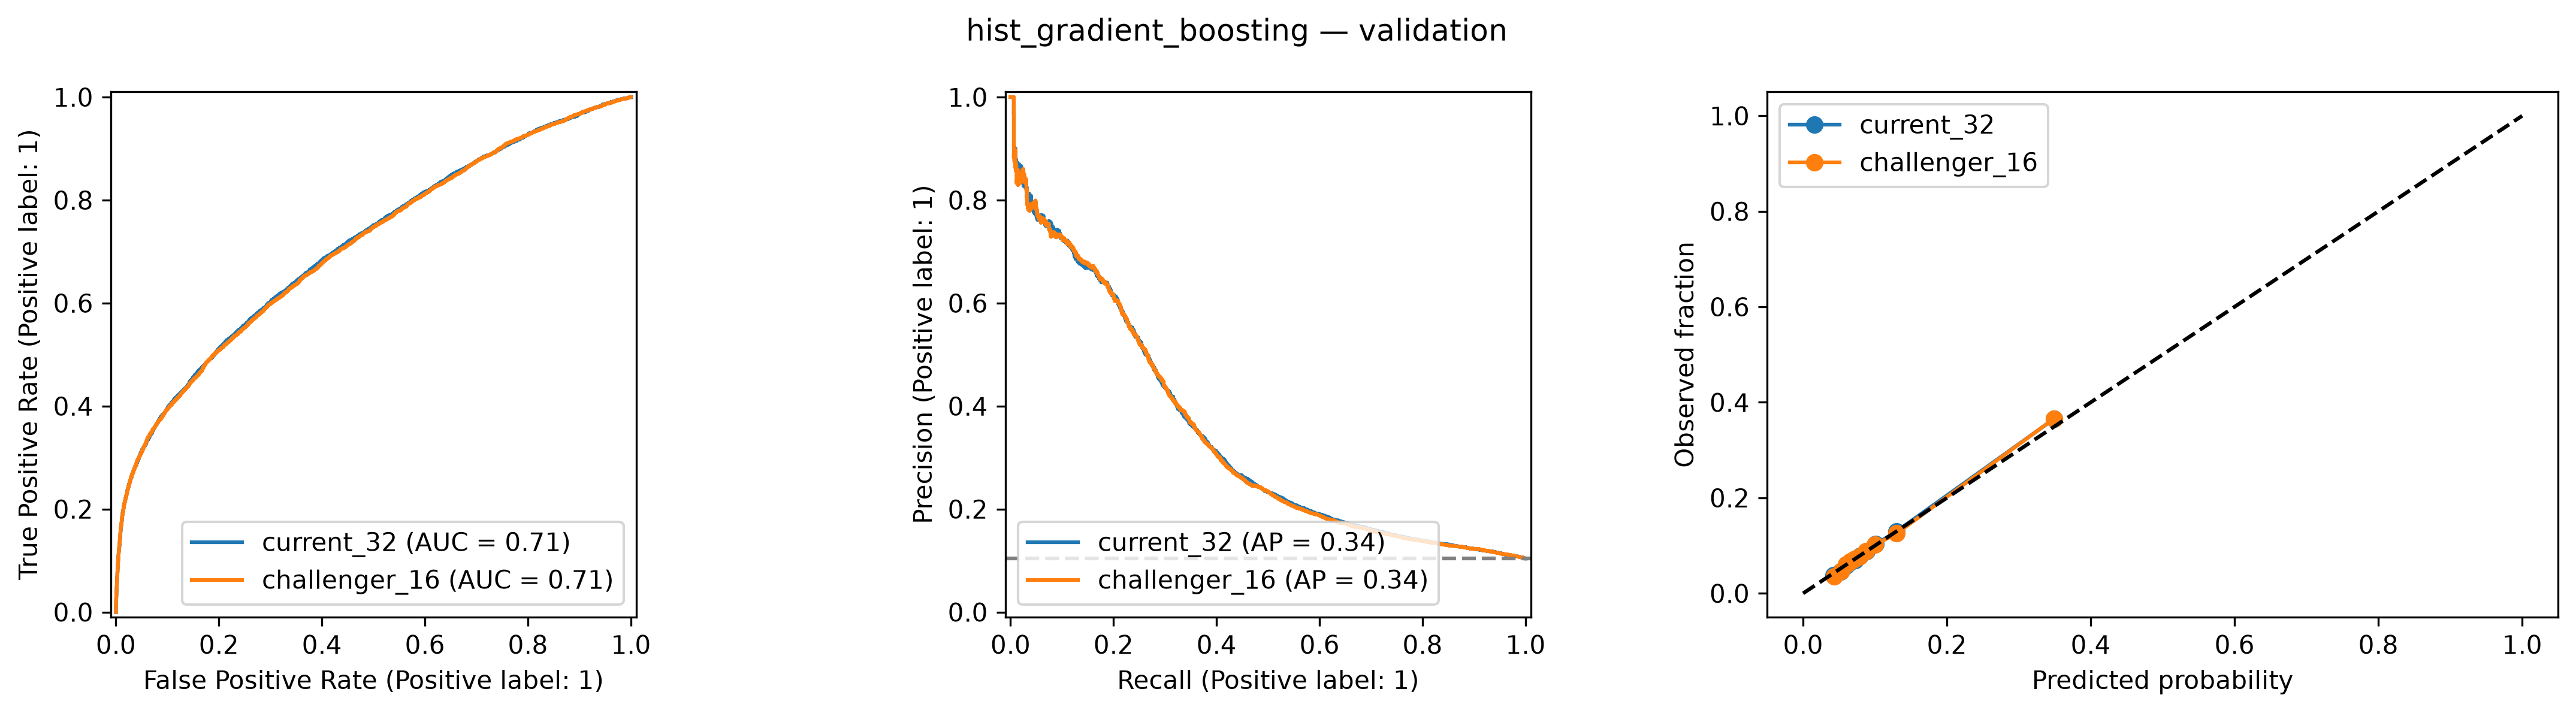

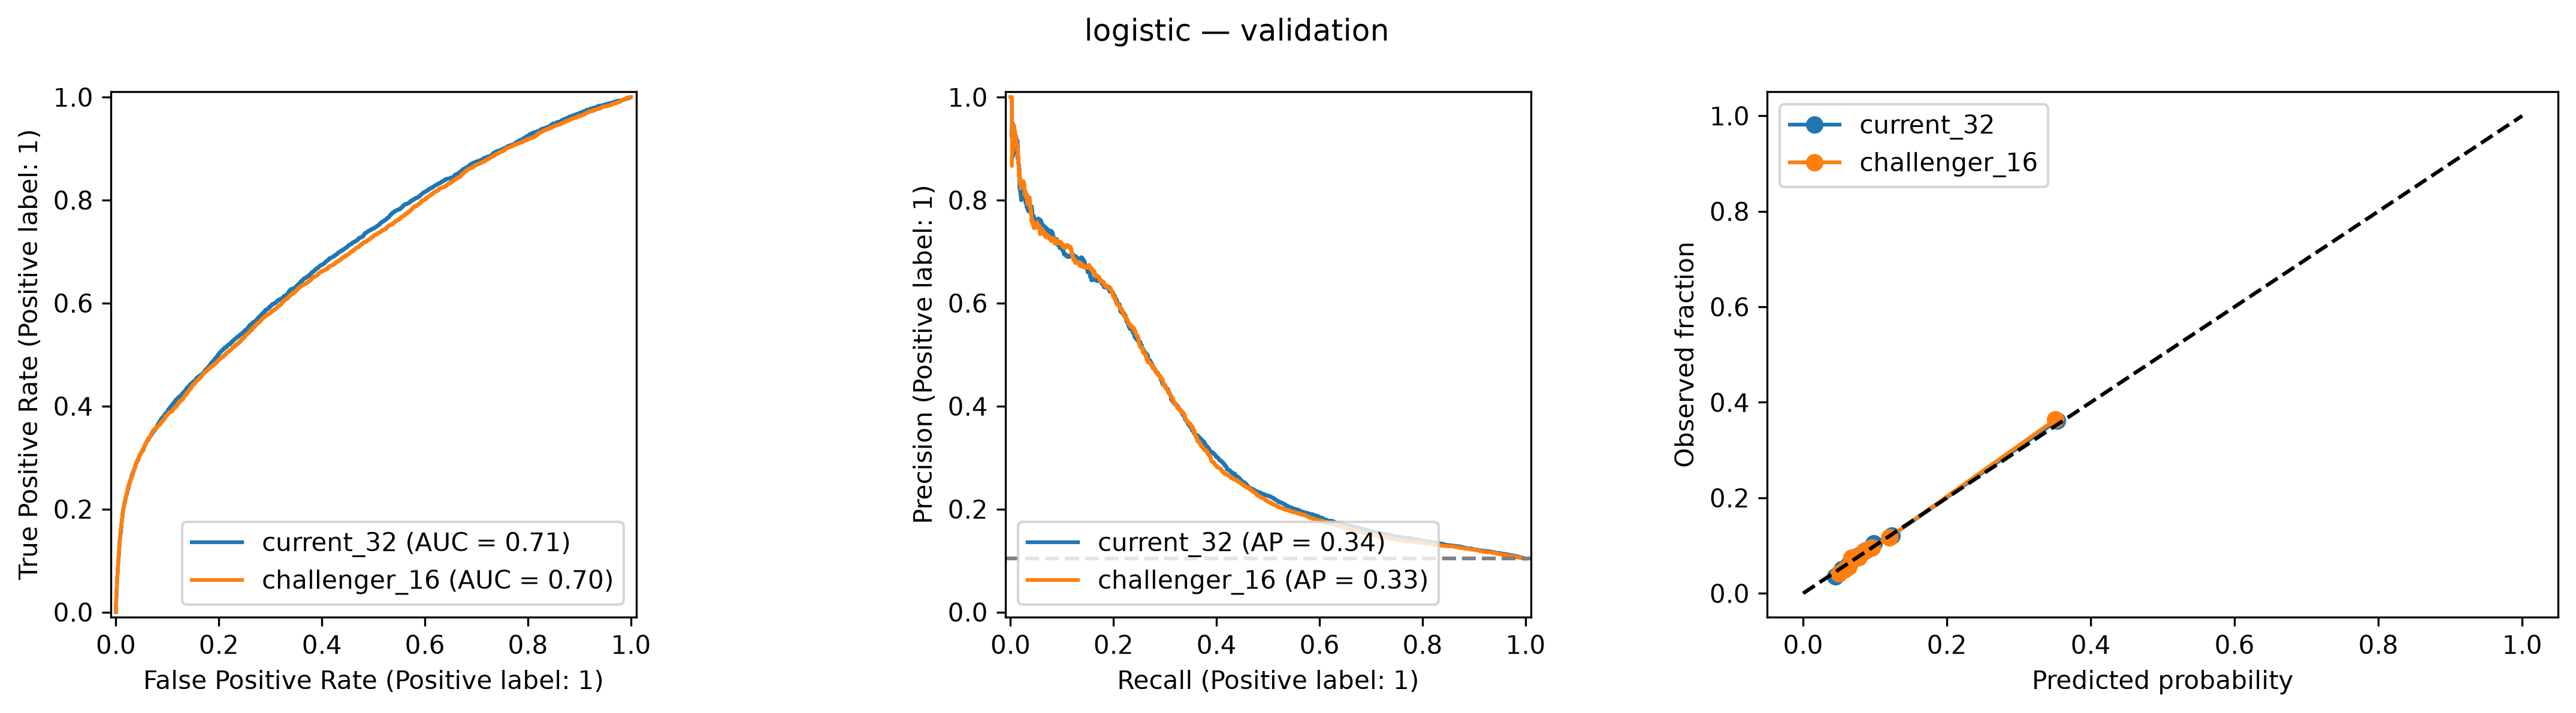

In [16]:
for family in models:
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for feature_set in feature_sets:
        p=predictions[f'{family}__{feature_set}']
        RocCurveDisplay.from_predictions(y_validation,p,name=feature_set,ax=axes[0])
        PrecisionRecallDisplay.from_predictions(y_validation,p,name=feature_set,ax=axes[1])
        fraction,mean=calibration_curve(y_validation,p,n_bins=10,strategy='quantile')
        axes[2].plot(mean,fraction,'o-',label=feature_set)
    axes[1].axhline(y_validation.mean(),linestyle='--',color='grey')
    axes[2].plot([0,1],[0,1],'k--');axes[2].set(xlabel='Predicted probability',ylabel='Observed fraction');axes[2].legend()
    fig.suptitle(family+' — validation');save_figure(family+'_curves')

## Confusion matrices at validation F2 thresholds

Counts and normalized matrices show missed preterm births and false alerts.

,precision,recall,f1-score,support
0,0.942545,0.596875,0.730901,40320.0000
1,0.165049,0.686538,0.266120,4680.0000
accuracy,0.606200,0.606200,0.606200,0.6062
macro avg,0.553797,0.641707,0.498510,45000.0000
weighted avg,0.861685,0.606200,0.682563,45000.0000


,precision,recall,f1-score,support
0,0.940101,0.637599,0.759850,40320.000000
1,0.172312,0.650000,0.272410,4680.000000
accuracy,0.638889,0.638889,0.638889,0.638889
macro avg,0.556207,0.643800,0.516130,45000.000000
weighted avg,0.860251,0.638889,0.709156,45000.000000


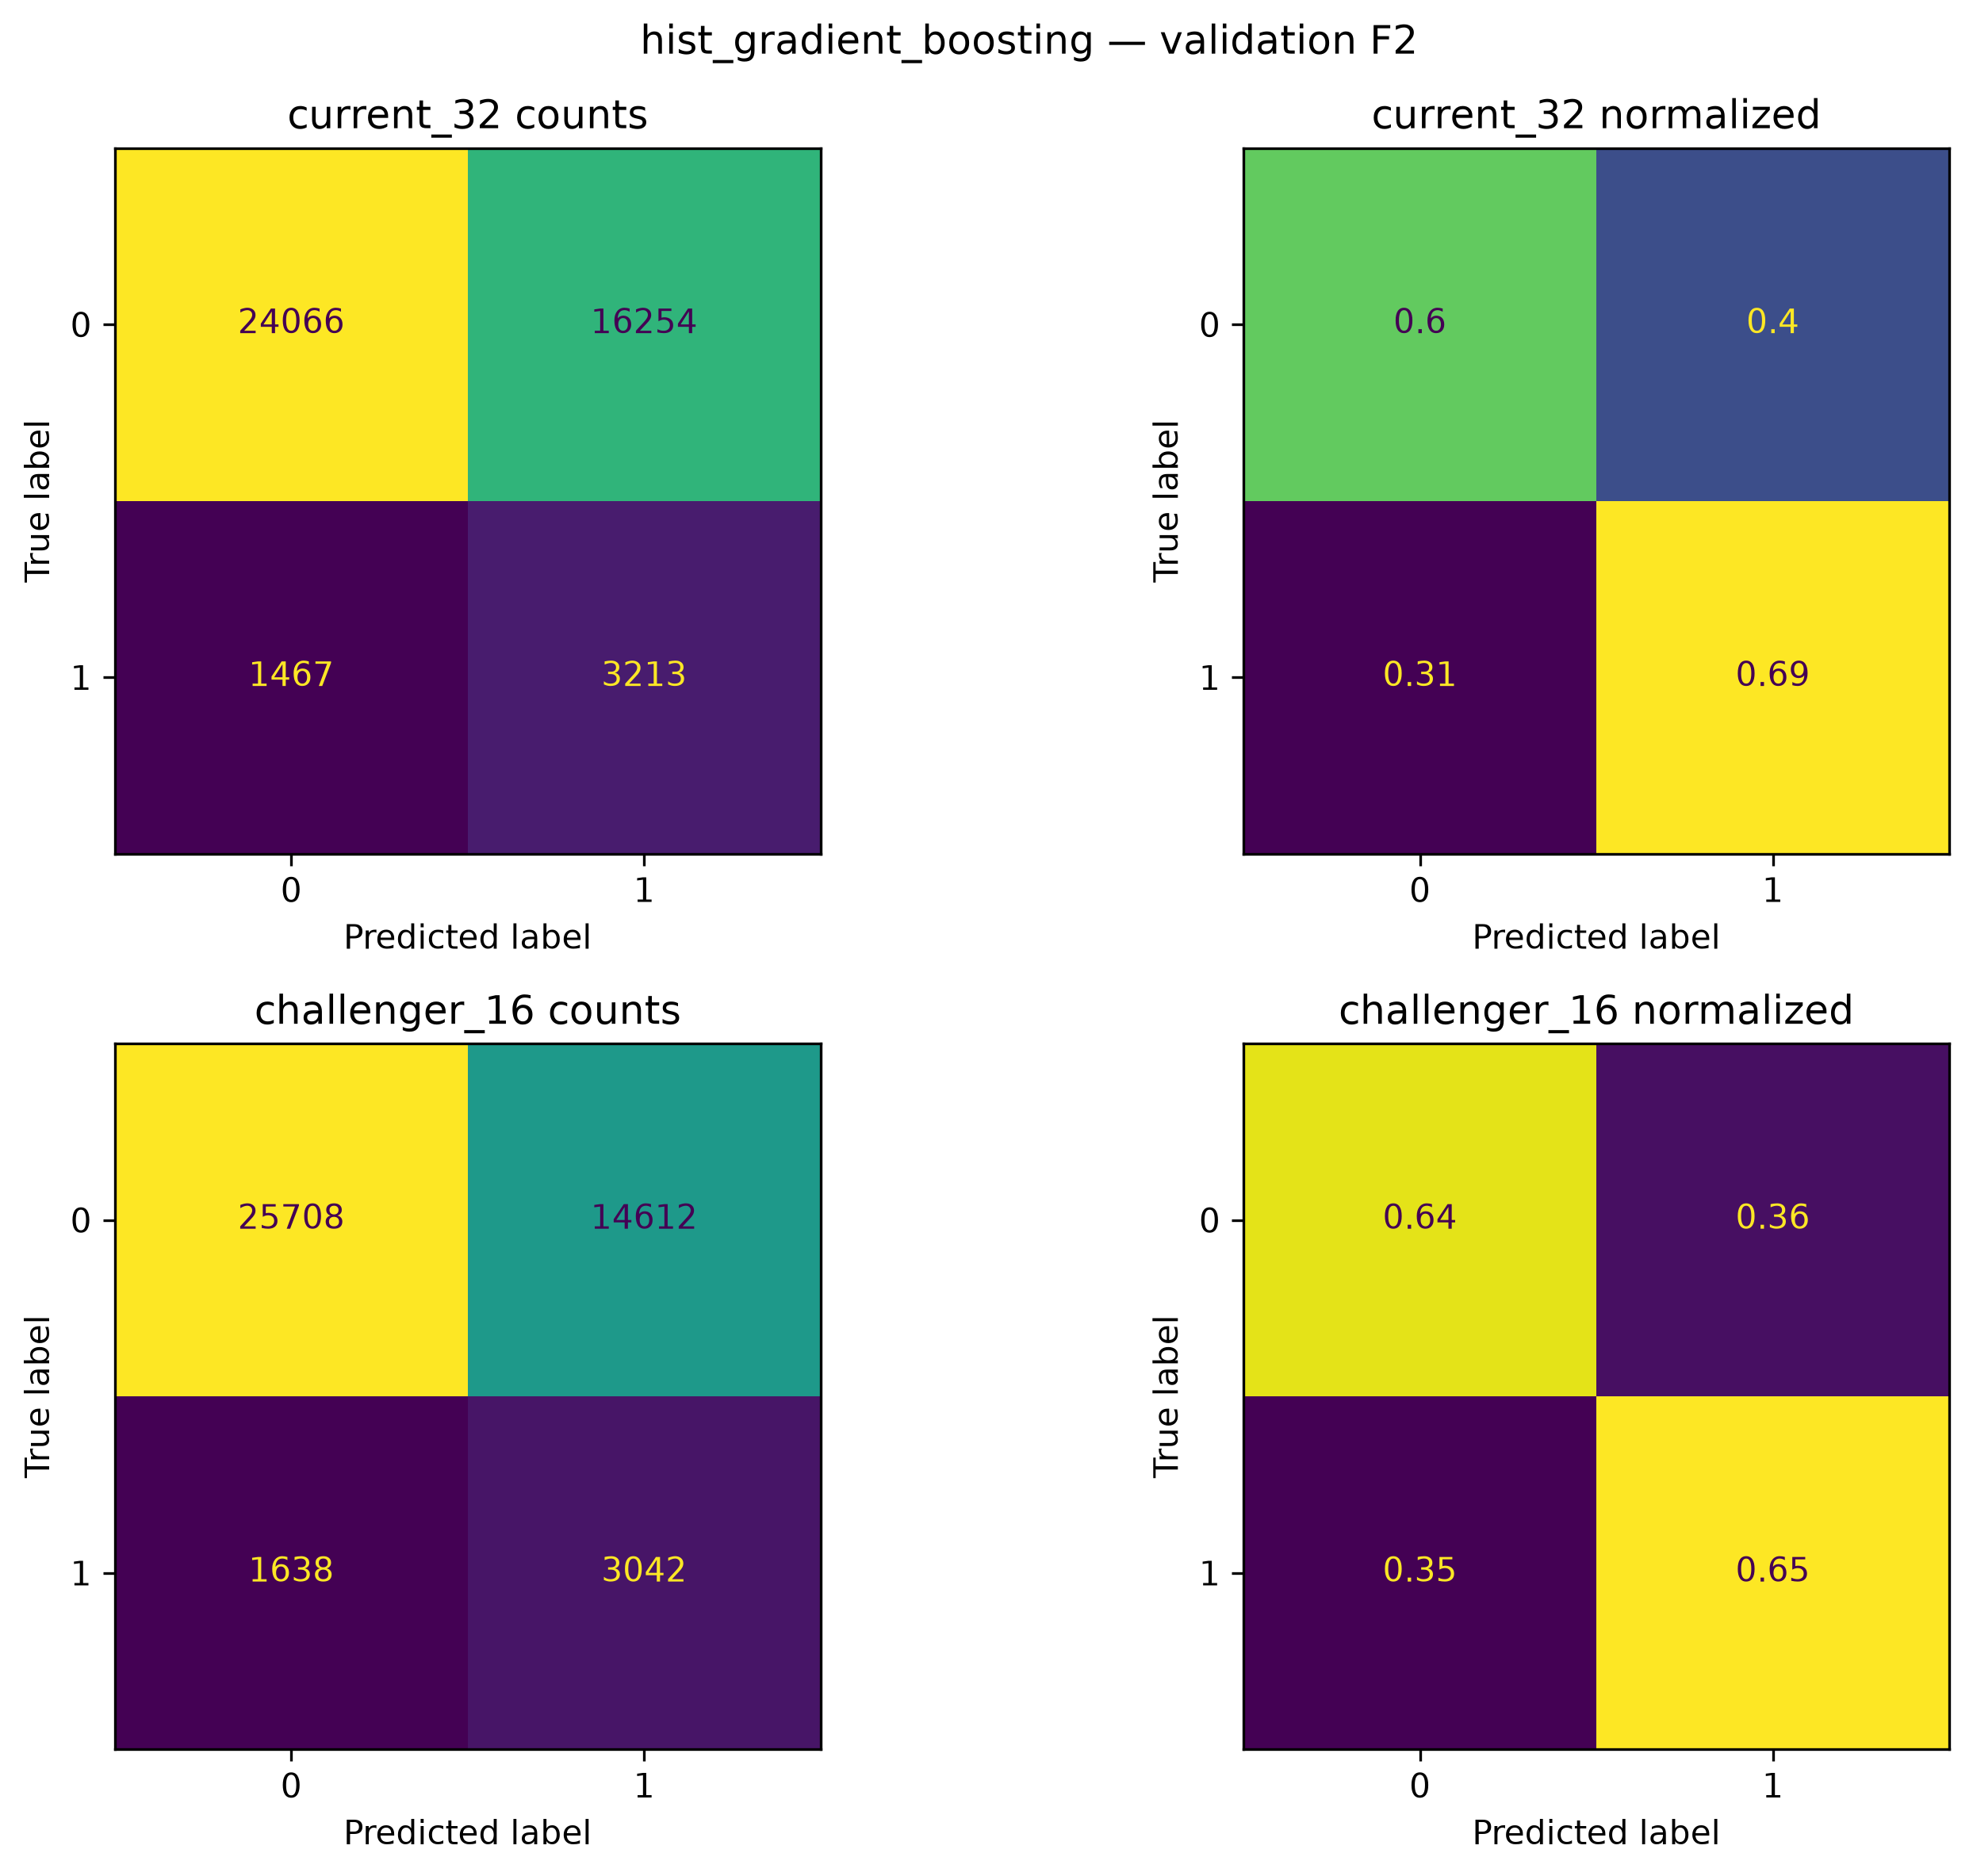

,precision,recall,f1-score,support
0,0.941554,0.586136,0.722501,40320.000000
1,0.161457,0.686538,0.261432,4680.000000
accuracy,0.596578,0.596578,0.596578,0.596578
macro avg,0.551506,0.636337,0.491966,45000.000000
weighted avg,0.860424,0.596578,0.674550,45000.000000


,precision,recall,f1-score,support
0,0.937761,0.639385,0.760349,40320.000000
1,0.169570,0.634402,0.267610,4680.000000
accuracy,0.638867,0.638867,0.638867,0.638867
macro avg,0.553666,0.636893,0.513979,45000.000000
weighted avg,0.857870,0.638867,0.709104,45000.000000


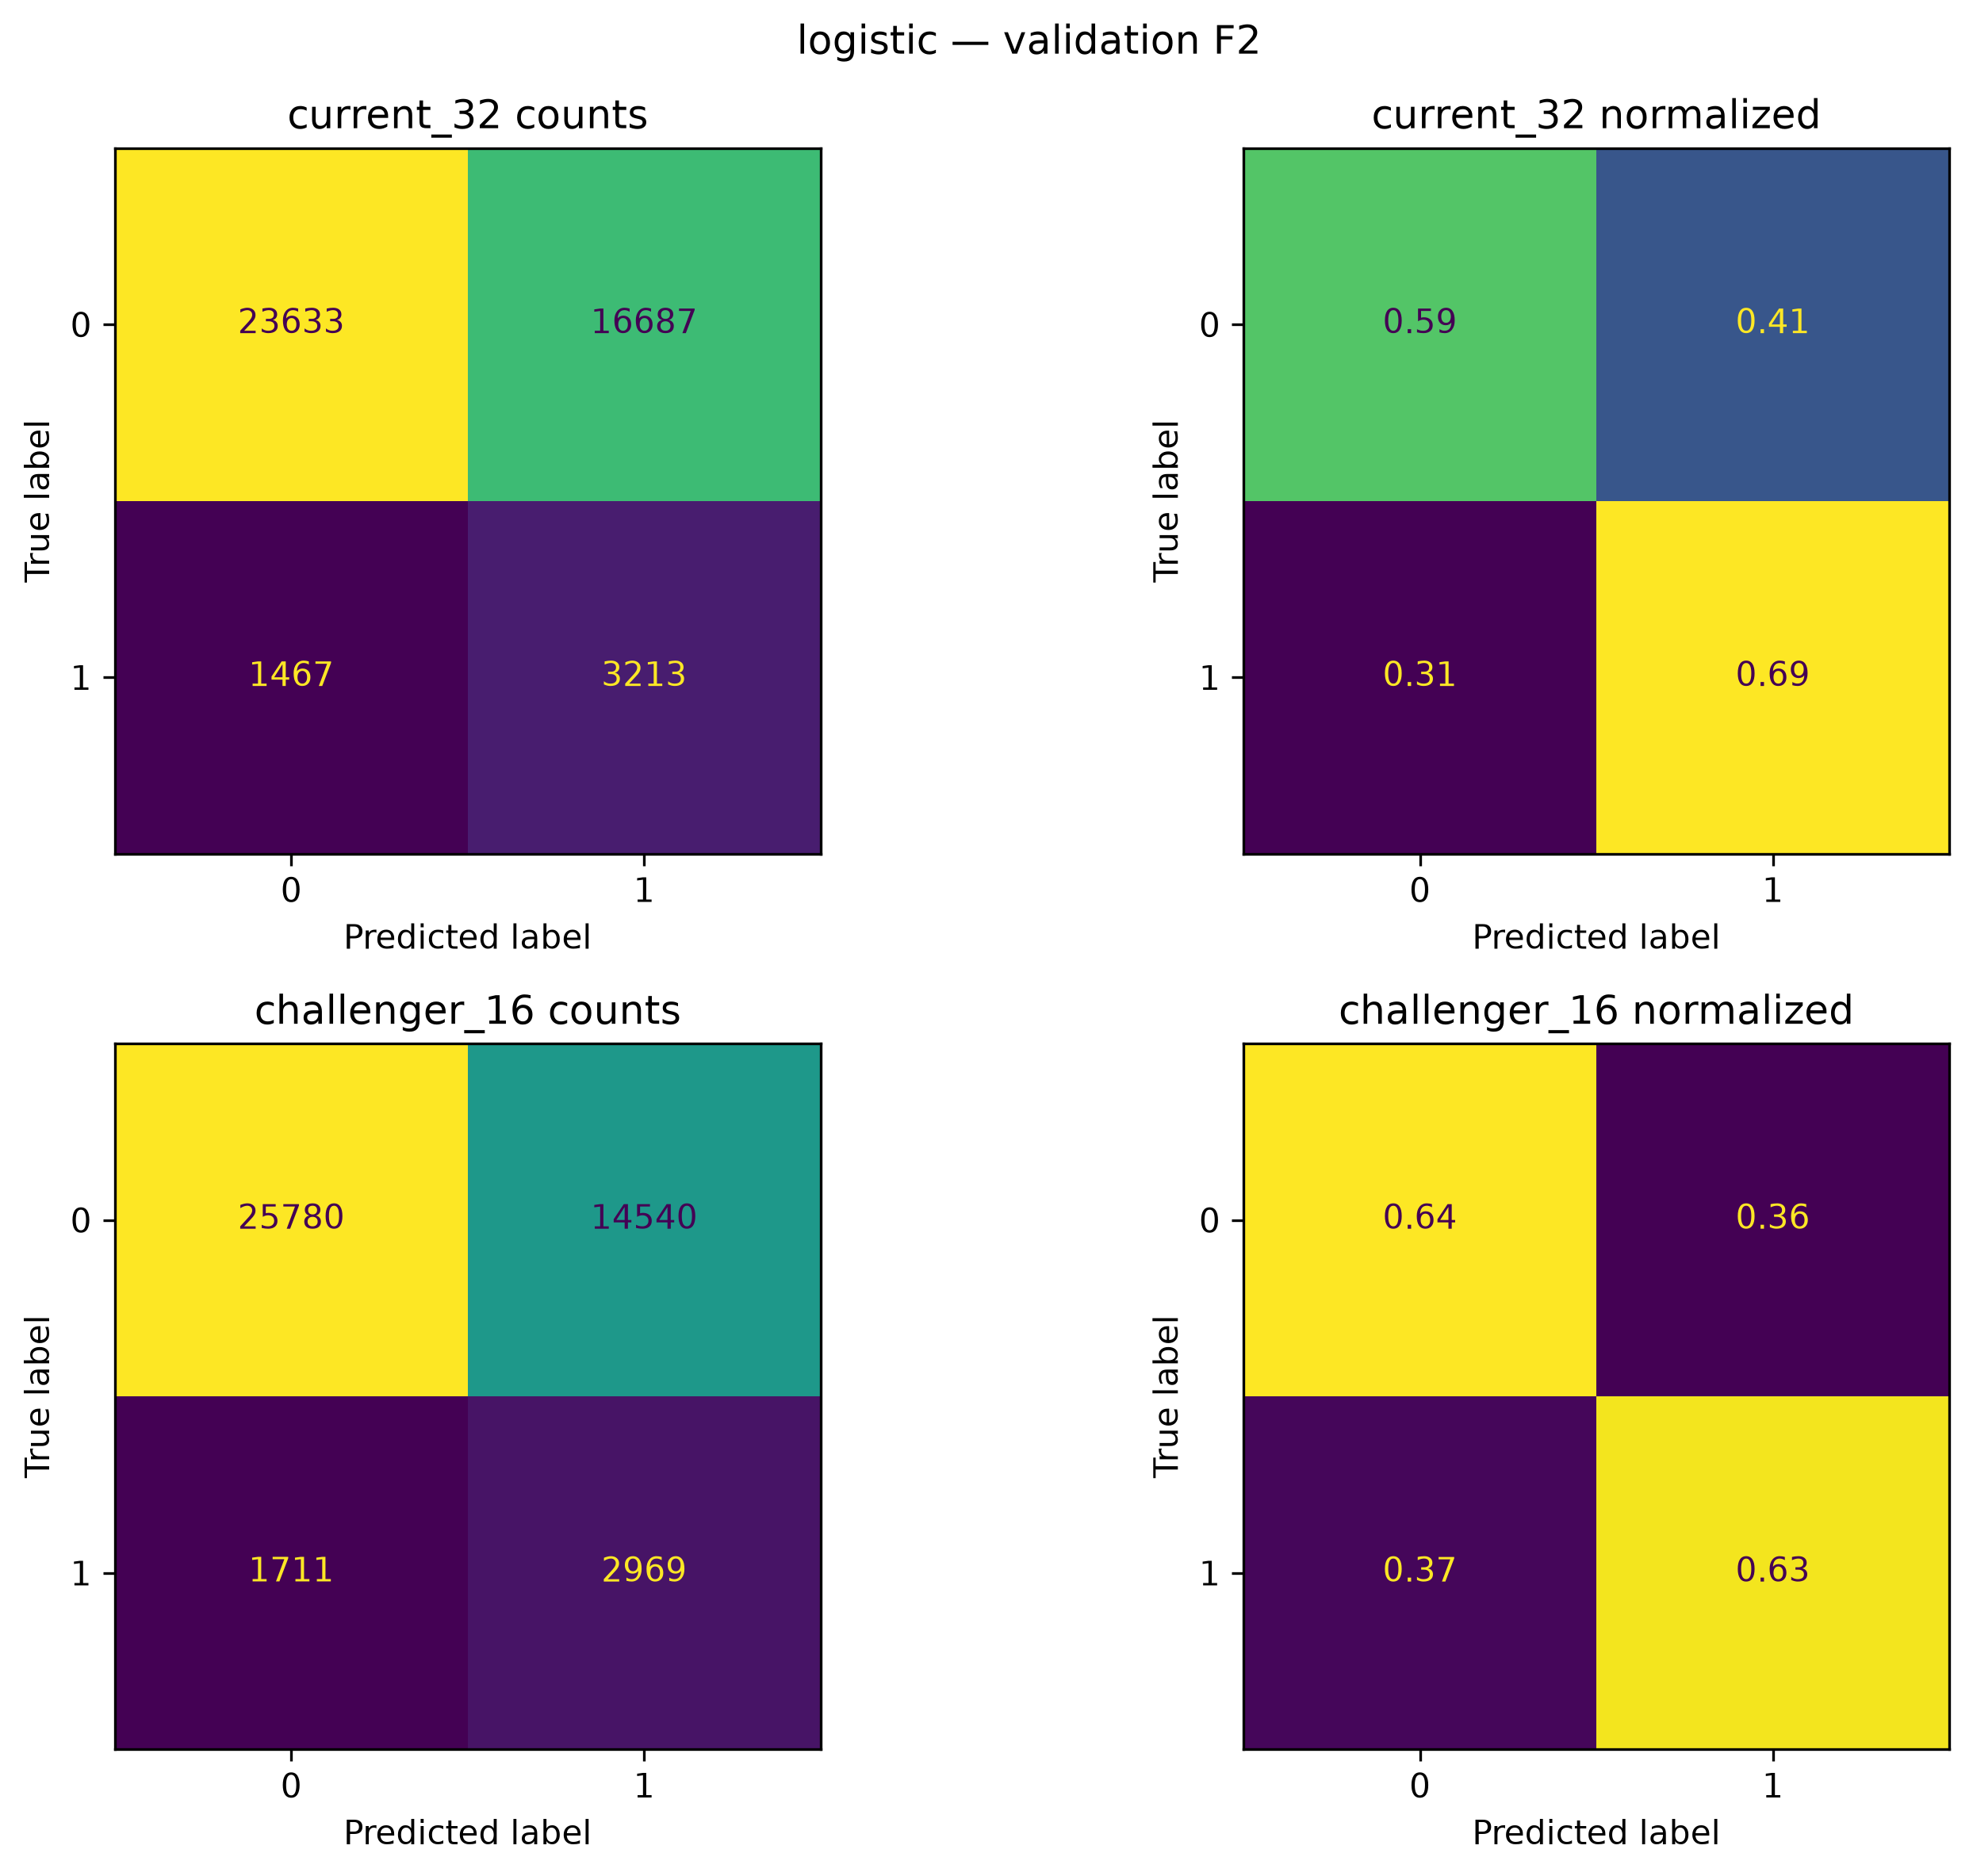

In [17]:
for family in models:
    fig,axes=plt.subplots(2,2,figsize=(10,8))
    for row,feature_set in enumerate(feature_sets):
        selected=f2_comparison.loc[f2_comparison.model.eq(family)&f2_comparison.feature_set.eq(feature_set)].iloc[0]
        p=predictions[f'{family}__{feature_set}'];pred=p>=selected.threshold
        ConfusionMatrixDisplay.from_predictions(y_validation,pred,ax=axes[row,0],colorbar=False)
        ConfusionMatrixDisplay.from_predictions(y_validation,pred,normalize='true',ax=axes[row,1],colorbar=False)
        axes[row,0].set_title(feature_set+' counts');axes[row,1].set_title(feature_set+' normalized')
        report=pd.DataFrame(classification_report(y_validation,pred,output_dict=True,zero_division=0)).T
        display(report)
        report.to_csv(TABLES/f'{family}__{feature_set}_classification.csv')
    fig.suptitle(family+' — validation F2');save_figure(family+'_confusion')

## Matched HGB learning curves

Same training-only folds and row budgets; no validation or test records are fitted.

,feature_set,training_rows,train_AP,train_AP_std,cv_AP,cv_AP_std
0,current_32,4000,0.495869,0.027728,0.287318,0.005767
1,current_32,16000,0.403391,0.022561,0.306872,0.005606
2,current_32,40000,0.379216,0.009211,0.323336,0.004126
3,challenger_16,4000,0.507931,0.040753,0.288493,0.004415
4,challenger_16,16000,0.404437,0.010413,0.310778,0.003901
5,challenger_16,40000,0.371881,0.006100,0.322649,0.003049


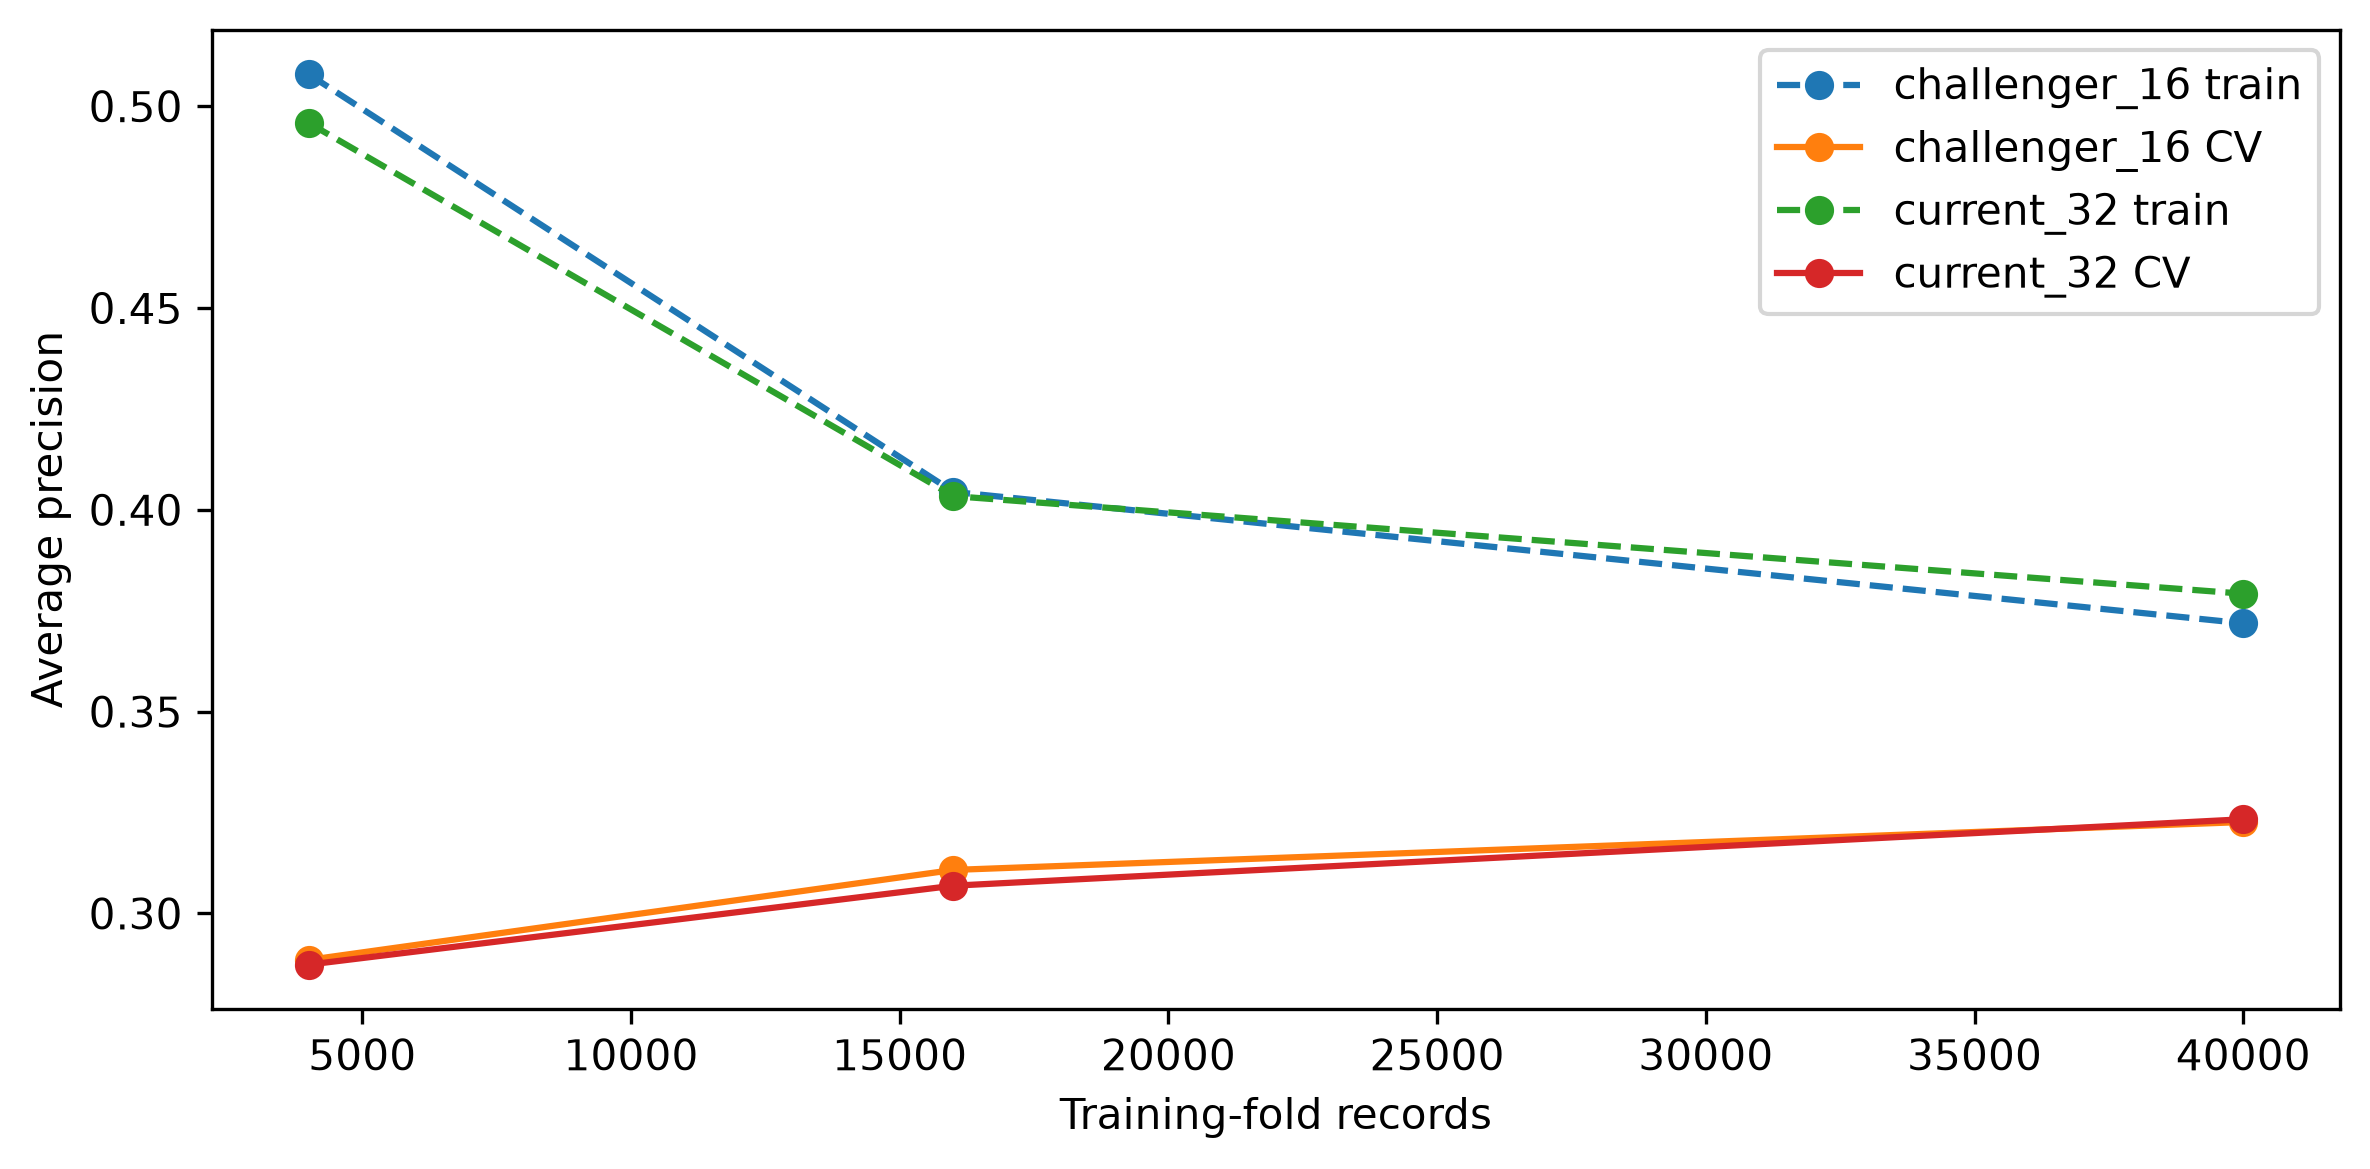

In [18]:
if RUN_STUDY:
    rows=[]
    for feature_set in feature_sets:
        x,_=inputs[feature_set]
        with threadpool_limits(limits=4):
            sizes,train_ap,fold_ap=learning_curve(pipelines[('hist_gradient_boosting',feature_set)],
                x.iloc[cv_ids],y_train[cv_ids],train_sizes=[.1,.4,1.],cv=cv_folds,
                scoring='average_precision',n_jobs=N_JOBS,shuffle=True,random_state=SEED,error_score='raise')
        for size,a,b in zip(sizes,train_ap,fold_ap):
            rows.append({'feature_set':feature_set,'training_rows':int(size),
                'train_AP':a.mean(),'train_AP_std':a.std(),'cv_AP':b.mean(),'cv_AP_std':b.std()})
    curves=pd.DataFrame(rows);curves.to_csv(TABLES/'learning_curves.csv',index=False)
else:
    curves=pd.read_csv(INPUT_TABLES/'learning_curves.csv')
display(curves)
for feature_set,g in curves.groupby('feature_set'):
    plt.plot(g.training_rows,g.train_AP,'o--',label=feature_set+' train')
    plt.plot(g.training_rows,g.cv_AP,'o-',label=feature_set+' CV')
plt.xlabel('Training-fold records');plt.ylabel('Average precision');plt.legend()
save_figure('matched_learning_curves')

## Reload new study pipelines

Reload and predict on real training examples only. No original model or preprocessing object is replaced.

In [19]:
if RUN_STUDY:
    reload_rows=[]
    for key in predictions:
        family,feature_set=key.split('__');x,_=inputs[feature_set]
        fitted=pipelines[(family,feature_set)]
        loaded=joblib.load(MODELS/f'{key}.joblib')
        before=fitted.predict_proba(x.head(5));after=loaded.predict_proba(x.head(5))
        np.testing.assert_allclose(before,after,rtol=0,atol=1e-12)
        reload_rows.append({'model':family,'feature_set':feature_set,'scope':'training rows',
            'rows':5,'max_absolute_difference':float(np.max(np.abs(before-after))),'passed':True})
    reload_proof=pd.DataFrame(reload_rows);reload_proof.to_csv(TABLES/'reload_proof.csv',index=False)
else:
    reload_proof=pd.read_csv(INPUT_TABLES/'reload_proof.csv')
display(reload_proof)
verify_protected()
print('Original final-test guard and prediction caches are unchanged.')

,model,feature_set,scope,rows,max_absolute_difference,passed
0,hist_gradient_boosting,current_32,training rows,5,0.0,True
1,hist_gradient_boosting,challenger_16,training rows,5,0.0,True
2,logistic,current_32,training rows,5,0.0,True
3,logistic,challenger_16,training rows,5,0.0,True


Original final-test guard and prediction caches are unchanged.


## Measured conclusion

Use the primary HGB result and report the LR control separately. An interval including zero does not establish superiority or equivalence.

In [20]:
for family in models:
    row=differences.loc[differences.model.eq(family)].iloc[0]
    ci=intervals.loc[intervals.model.eq(family)&intervals.metric.eq('delta_AP')].iloc[0]
    direction='higher' if row.delta_AP>0 else 'lower' if row.delta_AP<0 else 'equal'
    print(f"{family}: challenger AP is {direction}; delta={row.delta_AP:.6f}; conditional 95% interval [{ci.lower_95:.6f}, {ci.upper_95:.6f}].")
    if ci.interval_includes_zero:print('No established AP improvement or formal equivalence.')
print('Compare alert burden at matched recall before favoring either feature set.')
print('These results do not evaluate the lean schema in RF/SVM/neural models or justify a new test claim.')
print('This joint feature removal does not identify which individual omitted inputs caused a difference.')
run_log.finish()


hist_gradient_boosting: challenger AP is lower; delta=-0.001188; conditional 95% interval [-0.002912, 0.000600].
No established AP improvement or formal equivalence.
logistic: challenger AP is lower; delta=-0.003361; conditional 95% interval [-0.005230, -0.001296].
Compare alert burden at matched recall before favoring either feature set.
These results do not evaluate the lean schema in RF/SVM/neural models or justify a new test claim.
This joint feature removal does not identify which individual omitted inputs caused a difference.
